In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import math
import numpy as np

In [2]:
table = pd.read_csv('bangladesh_sme_1200_records_approved.csv')
table.columns

Index(['business_id', 'sector', 'business_age_years', 'legal_status',
       'division', 'location_type', 'employees_count', 'monthly_revenue_bdt',
       'monthly_profit_bdt', 'existing_loans', 'prior_loan_count',
       'late_payment_history', 'loan_purpose', 'loan_amount_bdt',
       'preferred_tenure_months', 'collateral_level', 'cashflow_stability',
       'missed_payment_last_12m', 'repayment_confidence', 'owner_education',
       'days_payable_outstanding', 'business_description',
       'loan_purpose_description', 'repayment_plan_description',
       'risk_factors_description', 'target_missed_payment', 'split',
       'approved'],
      dtype='str')

In [3]:
int(table['sector'].isna().sum())

0

In [4]:
for el in table.columns:
    print(int(table[el].isna().sum()))

0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0


<Axes: xlabel='sector', ylabel='Count'>

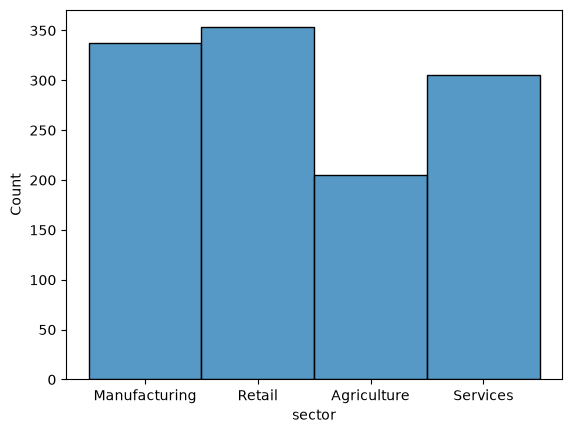

In [5]:
sns.histplot(table['sector'])

<Axes: xlabel='business_age_years', ylabel='Count'>

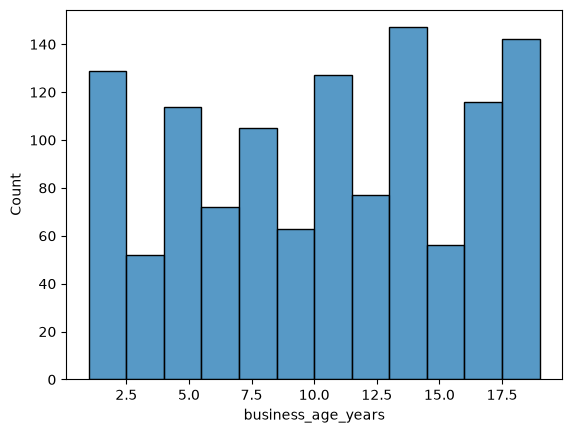

In [6]:
sns.histplot(table['business_age_years'])


<Axes: xlabel='legal_status', ylabel='Count'>

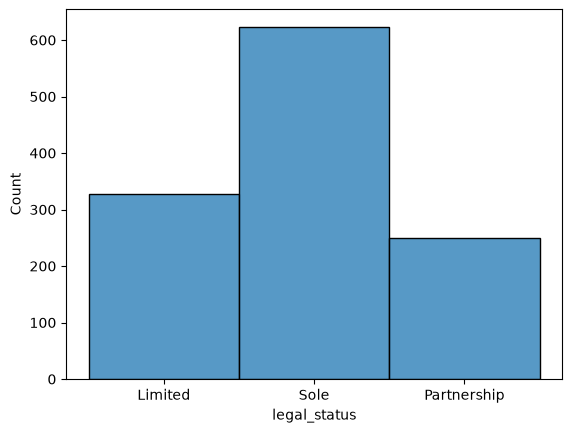

In [7]:
sns.histplot(table['legal_status'])

In [8]:
# for col in table.columns:
#     plt.figure(figsize=(6, 4))  # Размер одного графика
#     sns.histplot(table[col], kde=True)  # kde=True добавит линию распределения
#     plt.title(f"Распределение для {col}")
#     plt.show()

<Axes: xlabel='monthly_profit_bdt', ylabel='Count'>

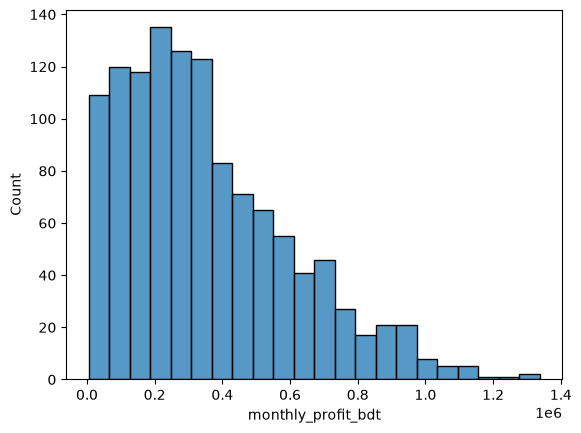

In [9]:
sns.histplot(table['monthly_profit_bdt'])

<Axes: ylabel='monthly_profit_bdt'>

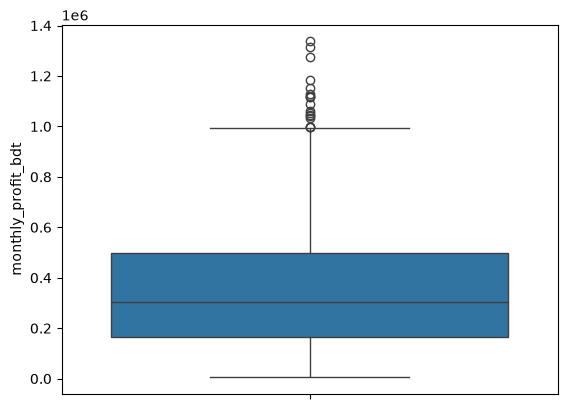

In [10]:
sns.boxplot(table['monthly_profit_bdt'])

In [11]:
# есть выбросы в monthly_profit 

In [12]:
table['monthly_profit_bdt'].max()

np.int64(1337403)

In [13]:
# новая таблица только с нужными столбцами
new_table = table.drop(columns=['prior_loan_count', 'late_payment_history', 'collateral_level', 'division', 'location_type', 'employees_count','cashflow_stability', 'missed_payment_last_12m', 'repayment_confidence', 'owner_education', 'days_payable_outstanding', 'business_description', 'loan_purpose_description', 'repayment_plan_description', 'risk_factors_description', 'target_missed_payment'])
new_table.columns

Index(['business_id', 'sector', 'business_age_years', 'legal_status',
       'monthly_revenue_bdt', 'monthly_profit_bdt', 'existing_loans',
       'loan_purpose', 'loan_amount_bdt', 'preferred_tenure_months', 'split',
       'approved'],
      dtype='str')

In [14]:
new_table = new_table.rename(columns={'sector': 'okved', 'legal_status':'legal_form', 
                                 'monthly_revenue_bdt': 'revenue', 'monthly_profit_bdt': 'net_profit', 
                                 'existing_loans': 'current_loans', 'loan_purpose': 'purpose',
                                 'loan_amount_bdt': 'amount', 
                                 'preferred_tenure_months': 'term_months', 'approved':'status'})
new_table.columns

Index(['business_id', 'okved', 'business_age_years', 'legal_form', 'revenue',
       'net_profit', 'current_loans', 'purpose', 'amount', 'term_months',
       'split', 'status'],
      dtype='str')

In [15]:
new_table.head(3)

,business_id,okved,business_age_years,legal_form,revenue,net_profit,current_loans,purpose,amount,term_months,split,status
0,SME0001,Manufacturing,15,Limited,403110,96506,Yes,Working capital,783644,30,train,Yes
1,SME0002,Retail,16,Sole,1562133,428067,Yes,Working capital,3745637,36,test,Yes
2,SME0003,Retail,17,Sole,655507,175415,Yes,Equipment,1542616,24,test,No


In [16]:
# перевести в рубли: revenue, net_profit, amount
new_table['revenue'] = np.ceil(new_table['revenue']*0.651)
new_table['net_profit'] = np.ceil(new_table['net_profit']*0.651)
new_table['amount'] = np.ceil(new_table['amount']*0.651)
new_table.head(4)

,business_id,okved,business_age_years,legal_form,revenue,net_profit,current_loans,purpose,amount,term_months,split,status
0,SME0001,Manufacturing,15,Limited,262425.0,62826.0,Yes,Working capital,510153.0,30,train,Yes
1,SME0002,Retail,16,Sole,1016949.0,278672.0,Yes,Working capital,2438410.0,36,test,Yes
2,SME0003,Retail,17,Sole,426736.0,114196.0,Yes,Equipment,1004244.0,24,test,No
3,SME0004,Agriculture,13,Sole,505151.0,112482.0,Yes,Expansion,1050891.0,18,train,Yes


In [17]:
train_set = new_table[new_table['split']=='train']
test_set = new_table[new_table['split']=='test']

In [18]:
train_set.head(3)

,business_id,okved,business_age_years,legal_form,revenue,net_profit,current_loans,purpose,amount,term_months,split,status
0,SME0001,Manufacturing,15,Limited,262425.0,62826.0,Yes,Working capital,510153.0,30,train,Yes
3,SME0004,Agriculture,13,Sole,505151.0,112482.0,Yes,Expansion,1050891.0,18,train,Yes
4,SME0005,Agriculture,1,Sole,664560.0,212959.0,Yes,Working capital,475680.0,6,train,Yes


In [19]:
test_set.head(3)

,business_id,okved,business_age_years,legal_form,revenue,net_profit,current_loans,purpose,amount,term_months,split,status
1,SME0002,Retail,16,Sole,1016949.0,278672.0,Yes,Working capital,2438410.0,36,test,Yes
2,SME0003,Retail,17,Sole,426736.0,114196.0,Yes,Equipment,1004244.0,24,test,No
6,SME0007,Retail,19,Sole,804217.0,110075.0,Yes,Expansion,640296.0,36,test,Yes


In [20]:
train_set.to_csv('train.csv', index=False)
test_set.to_csv('test.csv', index=False)

In [21]:
# тренируем модельку

In [22]:
df = new_table
df['legal_form'] = df["legal_form"].map({"Sole":0, "Limited": 1, "Partnership":2})
df['current_loans'] = df["current_loans"].map({"Yes":1, "No": 0})
df['purpose'] = df["purpose"].map({"Working capital":0, "Equipment": 1, "Expansion": 2, "Renovation":3, "Inventory":4})
df['status'] = df["status"].map({"Yes":1, "No": 0})
df.head(10)

,business_id,okved,business_age_years,legal_form,revenue,net_profit,current_loans,purpose,amount,term_months,split,status
0,SME0001,Manufacturing,15,1,262425.0,62826.0,1,0,510153.0,30,train,1
1,SME0002,Retail,16,0,1016949.0,278672.0,1,0,2438410.0,36,test,1
2,SME0003,Retail,17,0,426736.0,114196.0,1,1,1004244.0,24,test,0
3,SME0004,Agriculture,13,0,505151.0,112482.0,1,2,1050891.0,18,train,1
4,SME0005,Agriculture,1,0,664560.0,212959.0,1,0,475680.0,6,train,1
5,SME0006,Retail,19,0,1023186.0,336582.0,1,3,2345329.0,12,train,0
6,SME0007,Retail,19,0,804217.0,110075.0,1,2,640296.0,36,test,1
7,SME0008,Manufacturing,6,0,1715141.0,369825.0,1,0,3255000.0,12,train,0
8,SME0009,Retail,1,0,683261.0,102150.0,0,2,1458382.0,18,test,0
9,SME0010,Services,3,1,188175.0,30489.0,0,0,343795.0,6,train,0


In [23]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [24]:
print(df.isna().sum())


business_id           0
okved                 0
business_age_years    0
legal_form            0
revenue               0
net_profit            0
current_loans         0
purpose               0
amount                0
term_months           0
split                 0
status                0
dtype: int64


In [125]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

y = df['status']
X = df.drop(columns=['status', 'business_id', 'okved', 'split'])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

# --- ИСПРАВЛЕННЫЙ БЛОК С ОТСТУПАМИ ---
for col, coef in zip(X.columns, model.coef_[0]):
    print(f"Коэффициент для {col}: {coef:.4f}") # 4 пробела в начале строки

print(f"Свободный член: {model.intercept_[0]:.4f}\n") # Эта строка вне цикла
# -------------------------------------

y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
print(f"Доля правильных ответов (Accuracy): {accuracy * 100:.2f}%")

# Подробный отчет по классам 0 и 1
print("\nДетальный отчет (Classification Report):")
print(classification_report(y_test, y_pred))

Коэффициент для business_age_years: 0.1665
Коэффициент для legal_form: -0.0132
Коэффициент для revenue: 0.6950
Коэффициент для net_profit: 0.8979
Коэффициент для current_loans: -0.1477
Коэффициент для purpose: 0.0604
Коэффициент для amount: -1.5061
Коэффициент для term_months: 0.3364
Свободный член: 0.3417

Доля правильных ответов (Accuracy): 75.00%

Детальный отчет (Classification Report):
              precision    recall  f1-score   support

           0       0.74      0.65      0.69       104
           1       0.76      0.82      0.79       136

    accuracy                           0.75       240
   macro avg       0.75      0.74      0.74       240
weighted avg       0.75      0.75      0.75       240



In [126]:
X.columns

Index(['business_age_years', 'legal_form', 'revenue', 'net_profit',
       'current_loans', 'purpose', 'amount', 'term_months'],
      dtype='str')

In [127]:
import joblib

# Сохраняем модель и scaler в файлы
joblib.dump(model, 'logistic_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
print("\n[Успешно] Модель 'logistic_model.pkl' и скалер 'scaler.pkl' сохранены!")



[Успешно] Модель 'logistic_model.pkl' и скалер 'scaler.pkl' сохранены!
